# YAD-AfroXLMR — Efficiency, windowing and output guarantees

This notebook produces the numbers that need the models themselves:

**Part A — CPU, tokenizer only**
- A1. Setup
- A2. Truncation check: how many test sentences exceed the 256-token input limit

**Part B — GPU (A100), needs the checkpoints**
- B1. Load the models and record the GPU and parameter counts
- B2. Inference functions
- B3. Check the loaded checkpoint reproduces the released predictions
- B4. Speed and memory against sentence length (time and space complexity)
- B5. Full test set timing
- B6. Windowed inference for all six configurations
- B7. Windowed inference for mT5 on the long sentences
- B8. Score the regenerated predictions

**Checkpoints.** The six YAD-AfroXLMR checkpoints are hosted on Hugging Face as `Jehohshua/YAD-AfroXLMR-{A,B0,B1,B2,B3,C}` and are **not publicly released**. Part B runs only for an account with access. Every accuracy and preservation number in the paper can be reproduced without them from `evaluate.ipynb`, using the released predictions.

**Saved outputs.** The outputs shown are from the October 2026 run on an NVIDIA A100-SXM4-40GB.

# Part A — CPU, tokenizer only

## A1. Setup

In [2]:
import os, sys

# On Colab, get the repository first. Locally this cell does nothing.
#   - If yad-afroxlmr-eval*.zip has been uploaded anywhere under /content, it is unzipped and used.
#   - Otherwise the repository is cloned from GitHub.
REPO_URL = 'https://github.com/JehohshuaA/yad-afroxlmr-eval.git'
if 'google.colab' in sys.modules and not os.path.exists('yad_eval.py'):
    import glob
    found = glob.glob('/content/**/yad_eval.py', recursive=True)
    zips = sorted(glob.glob('/content/**/yad-afroxlmr-eval*.zip', recursive=True))
    if not found and zips:
        !unzip -q -o "{zips[-1]}" -d /content
        found = glob.glob('/content/**/yad_eval.py', recursive=True)
    if not found:
        !git clone -q {REPO_URL} /content/yad-afroxlmr-eval
        found = glob.glob('/content/**/yad_eval.py', recursive=True)
    if not found:
        raise RuntimeError(f'Could not get the repository. Check that {REPO_URL} exists and is public, '
                           'or upload yad-afroxlmr-eval.zip (folder icon, left), wait for the upload '
                           'to finish, and run this cell again.')
    %cd {os.path.dirname(found[0])}
    !pip install -q -r requirements.txt

import time, random, unicodedata
from yad_eval import (SYSTEMS, MARKS, read_lines, save_csv, score_folded,
                      clusters, fold_underdot, strip_marks, preservation)

OUT_DIR = 'results'
os.makedirs(OUT_DIR, exist_ok=True)

src_lines  = [l.strip() for l in read_lines('data/unyo.txt')]   # undiacritized input
gold_lines = read_lines('data/dcyo.txt')                         # diacritized reference
released   = {s: read_lines(f'predictions/{s}.txt') for s in SYSTEMS}
assert len(src_lines) == len(gold_lines) == 3330

# Checkpoints (private; see the note at the top)
HF_REPOS = {s: f'Jehohshua/YAD-AfroXLMR-{s}' for s in ['B0', 'B1', 'B2', 'B3', 'A', 'C']}
BASE_TOKENIZER = 'Davlan/afro-xlmr-base'
MT5_NAME = 'Davlan/mT5_base_yoruba_adr'

MAXLEN = 256          # input limit used in training and evaluation
LIMIT  = MAXLEN - 2   # tokens left for text after the start and end tokens

/content/yad-afroxlmr-eval


## A2. Truncation check

The model reads each character as a separate item and the input is cut at 256 tokens, which is roughly 254 characters. Characters after the cut are still copied to the output, so the letters are preserved, but the model never sees them, so they receive no diacritics.

This cell counts how many test sentences are longer than the cut and how many reference diacritic positions fall after it. It needs only the public AfroXLMR tokenizer. These are the sentences that B6 and B7 label in windows.

In [3]:
from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained(BASE_TOKENIZER)

def cut_position(text, max_length=MAXLEN):
    """Index of the first character the model does not see (len(text) if none is cut)."""
    chars = list(text)
    enc = tok([chars], is_split_into_words=True, truncation=True, max_length=max_length)
    seen = [w for w in enc.word_ids(0) if w is not None]
    last = max(seen) if seen else -1
    return len(chars) if last >= len(chars) - 1 else last + 1

cuts = [cut_position(s) for s in src_lines]
long_lines = [i for i, (s, c) in enumerate(zip(src_lines, cuts)) if s[c:].strip()]

gold_total = gold_after = 0
usable = []
for i, (s, g) in enumerate(zip(src_lines, gold_lines)):
    gc = clusters(fold_underdot(g.strip()))
    if len(gc) != len(s):          # letters do not line up one-to-one; skip
        continue
    usable.append(i)
    gold_total += sum(1 for _, m in gc if m)
    gold_after += sum(1 for _, m in gc[cuts[i]:] if m)

print(f"Lines longer than the cut: {len(long_lines)} / {len(src_lines)} "
      f"({100*len(long_lines)/len(src_lines):.2f}%)")
print(f"Lines checked (letters line up with the source): {len(usable)} / {len(src_lines)}")
print(f"Characters after the cut: {sum(len(src_lines[i]) - cuts[i] for i in long_lines):,}")
print(f"Reference diacritic positions after the cut: {gold_after:,} / {gold_total:,} "
      f"({100*gold_after/gold_total:.2f}% of all diacritic positions)")

save_csv([{'lines cut': len(long_lines), 'characters after cut': sum(len(src_lines[i]) - cuts[i] for i in long_lines),
           'gold positions after cut': gold_after, 'gold positions total': gold_total,
           'share after cut (%)': round(100*gold_after/gold_total, 2)}], f'{OUT_DIR}/truncation_check.csv');

config.json:   0%|          | 0.00/707 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/398 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/9.08M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Lines longer than the cut: 72 / 3330 (2.16%)
Lines checked (letters line up with the source): 3330 / 3330
Characters after the cut: 3,907
Reference diacritic positions after the cut: 1,141 / 119,533 (0.95% of all diacritic positions)


# Part B — GPU (A100), needs the checkpoints

## B1. Load the models

Loads Configuration A from Hugging Face. Access to the private repositories needs a Hugging Face token with read access: on Colab, add it as the secret `HF_TOKEN`; elsewhere, run `huggingface-cli login` or set the `HF_TOKEN` environment variable.

In [4]:
import torch
from transformers import AutoModelForTokenClassification, AutoModelForSeq2SeqLM

assert torch.cuda.is_available(), 'No GPU. On Colab: Runtime -> Change runtime type -> A100.'
device = 'cuda'
GPU = torch.cuda.get_device_name(0)
print('GPU:', GPU)

if 'google.colab' in sys.modules and not os.environ.get('HF_TOKEN'):
    try:
        from google.colab import userdata
        os.environ['HF_TOKEN'] = userdata.get('HF_TOKEN')
    except Exception:
        pass

def load_checkpoint(name):
    repo = HF_REPOS[name]
    try:
        return AutoModelForTokenClassification.from_pretrained(repo).to(device).eval()
    except OSError as e:
        raise RuntimeError(
            f'Could not load {repo}. The YAD-AfroXLMR checkpoints are not publicly released YET, kindly check back after the models have been published '
            'Every accuracy and preservation result '
            'can be reproduced without them in evaluate.ipynb.') from e

afro = load_checkpoint('A')
try:
    afro_tok = AutoTokenizer.from_pretrained(HF_REPOS['A'])
except OSError:
    afro_tok = tok

mt5_tok = AutoTokenizer.from_pretrained(MT5_NAME)
mt5 = AutoModelForSeq2SeqLM.from_pretrained(MT5_NAME).to(device).eval()

AFRO_PARAMS = sum(p.numel() for p in afro.parameters())
MT5_PARAMS  = sum(p.numel() for p in mt5.parameters())
print(f'AfroXLMR parameters: {AFRO_PARAMS:,}')
print(f'mT5 parameters:      {MT5_PARAMS:,}')

GPU: NVIDIA A100-SXM4-80GB


config.json:   0%|          | 0.00/1.04k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/450 [00:00<?, ?B/s]

... (8 outputs left out)

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/284 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


AfroXLMR parameters: 277,457,670
mT5 parameters:      582,401,280


## B2. Inference functions

Our model predicts one of six classes for each character, taken from the first sub-token of that character. mT5 uses greedy decoding with a maximum length of 256, as in the matched benchmark.

In [5]:
DIAC_LABELS = ['none', 'acute', 'grave', 'underdot', 'underdot+acute', 'underdot+grave']
id2diac = dict(enumerate(DIAC_LABELS))
UNDERDOT, ACUTE, GRAVE = '\u0323', '\u0301', '\u0300'
CLASS_TO_MARKS = {'none': '', 'acute': ACUTE, 'grave': GRAVE, 'underdot': UNDERDOT,
                  'underdot+acute': UNDERDOT + ACUTE, 'underdot+grave': UNDERDOT + GRAVE}

def predict_labels(char_lists, batch_size=1, fp16=False, max_length=MAXLEN):
    """One class id per character. Characters past the cut get class 0 (none)."""
    out = []
    for i in range(0, len(char_lists), batch_size):
        batch = char_lists[i:i + batch_size]
        enc = afro_tok(batch, is_split_into_words=True, return_tensors='pt',
                       padding=True, truncation=True, max_length=max_length).to(device)
        with torch.no_grad(), torch.autocast('cuda', dtype=torch.float16, enabled=fp16):
            preds = afro(**enc).logits.argmax(-1).tolist()
        for b in range(len(batch)):
            first, prev = {}, None
            for ti, w in enumerate(enc.word_ids(batch_index=b)):
                if w is not None and w != prev:
                    first[w] = preds[b][ti]
                prev = w
            out.append([first.get(j, 0) for j in range(len(batch[b]))])
    return out

def render(chars, labels):
    """Attach the marks for each predicted class to its character."""
    res = []
    for ch, lab in zip(chars, labels):
        marks = CLASS_TO_MARKS[id2diac[lab]]
        res.append(unicodedata.normalize('NFC', ch + marks) if marks and ch.isalpha() else ch)
    return ''.join(res)

def afro_one(text):
    """Batch size 1, full precision (single window)."""
    return render(list(text), predict_labels([list(text)])[0])

def afro_batch(texts, batch_size=16, fp16=True):
    labs = predict_labels([list(t) for t in texts], batch_size=batch_size, fp16=fp16)
    return [render(list(t), l) for t, l in zip(texts, labs)]

def mt5_one(text):
    """Returns (output text, input tokens, decoder steps)."""
    inp = mt5_tok(text, return_tensors='pt', truncation=True, max_length=MAXLEN).to(device)
    with torch.no_grad():
        out = mt5.generate(**inp, max_length=MAXLEN)
    return mt5_tok.decode(out[0], skip_special_tokens=True), inp['input_ids'].shape[1], out.shape[1] - 1

def mt5_batch(texts, batch_size=16):
    res = []
    for i in range(0, len(texts), batch_size):
        inp = mt5_tok(texts[i:i + batch_size], return_tensors='pt', padding=True,
                      truncation=True, max_length=MAXLEN).to(device)
        with torch.no_grad(), torch.autocast('cuda', dtype=torch.float16):
            out = mt5.generate(**inp, max_length=MAXLEN)
        res += mt5_tok.batch_decode(out, skip_special_tokens=True)
    return res

print('Test (ours):', afro_one('Kini mo ma fiyin baba to to mi si ona iye.'))
print('Test (mT5): ', mt5_one('Kini mo ma fiyin baba to to mi si ona iye.')[0])

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.33GB            

model.safetensors: downloading bytes:           |  0.00B            

Test (ours): Kíni mo má fiyín baba tó tó mi sí ọ̀nà ìyè.
Test (mT5):  Kíni mo má fìyìn bàbá tó tọ́ mi sí ọ̀nà ìyè.


## B3. Check the checkpoint reproduces the released predictions

The first 200 test lines that fit within the input limit (from A2) are run again and compared with `predictions/A.txt`.


In [6]:
idx = [i for i, s in enumerate(src_lines) if cuts[i] == len(s)][:200]   # lines not cut (A2)
same = sum(unicodedata.normalize('NFC', afro_one(src_lines[i])) ==
           unicodedata.normalize('NFC', released['A'][i].strip()) for i in idx)
print(f'Matches released Config A predictions: {same} / 200')
print('OK - correct checkpoint.' if same >= 198 else 'STOP - not the checkpoint that produced the released predictions.')

Matches released Config A predictions: 200 / 200
OK - correct checkpoint.


## B4. Speed and memory against sentence length

The test sentences are grouped by length, and forty sentences per group (random seed 42) are run one at a time on both models. For each sentence we record:

- **time**: wall-clock seconds, with the GPU synchronised before and after
- **model passes**: our model always makes 1; mT5 makes one per output token (its decoder steps)
- **peak extra memory**: the most GPU memory used on top of the loaded weights, in MB

Timings use single-window inference, as reported in the paper. Our time and memory should stay nearly flat as sentences get longer. mT5's time climbs with length because it makes more passes, and its memory climbs because it keeps everything it has generated so far.

In [7]:
random.seed(42)
BUCKETS = {'< 50': (0, 50), '50-100': (50, 100), '100-200': (100, 200), '200+': (200, 10**6)}
sample = {}
for b, (lo, hi) in BUCKETS.items():
    pool = [s for s in src_lines if lo <= len(s) < hi]
    sample[b] = random.sample(pool, min(40, len(pool)))
    print(f'{b:<8} {len(pool):>5} sentences in the test set, {len(sample[b])} sampled')

def measure(fn, text):
    torch.cuda.synchronize()
    base = torch.cuda.memory_allocated()
    torch.cuda.reset_peak_memory_stats()
    t0 = time.perf_counter()
    result = fn(text)
    torch.cuda.synchronize()
    dt = time.perf_counter() - t0
    peak = (torch.cuda.max_memory_allocated() - base) / 2**20
    return result, dt, peak

for _ in range(3):                      # warm-up
    afro_one(src_lines[0]); mt5_one(src_lines[0])

rows = []
for b, sents in sample.items():
    for s in sents:
        _, t_a, m_a = measure(afro_one, s)
        n_tok = len(afro_tok([list(s)], is_split_into_words=True,
                             truncation=True, max_length=MAXLEN)['input_ids'][0])
        rows.append({'model': 'ours', 'bucket': b, 'chars': len(s), 'input tokens': n_tok,
                     'model passes': 1, 'seconds': t_a, 'peak extra MB': m_a})
        (_, n_in, steps), t_m, m_m = measure(mt5_one, s)
        rows.append({'model': 'mT5', 'bucket': b, 'chars': len(s), 'input tokens': n_in,
                     'model passes': steps, 'seconds': t_m, 'peak extra MB': m_m})
    print(f'done: {b}')
save_csv(rows, f'{OUT_DIR}/length_scaling_per_sentence.csv')
print(f'Saved: {OUT_DIR}/length_scaling_per_sentence.csv')

def mean(xs): return sum(xs) / len(xs)
summary = []
print(f"\n{'Length':<9}{'n':>4}{'ours s':>10}{'mT5 s':>10}{'ratio':>8}"
      f"{'mT5 passes':>12}{'ours MB':>10}{'mT5 MB':>10}")
for b in BUCKETS:
    a = [r for r in rows if r['bucket'] == b and r['model'] == 'ours']
    m = [r for r in rows if r['bucket'] == b and r['model'] == 'mT5']
    ta, tm = mean([r['seconds'] for r in a]), mean([r['seconds'] for r in m])
    row = {'length': b, 'n': len(a), 'ours s/sent': round(ta, 4), 'mT5 s/sent': round(tm, 4),
           'ratio': round(tm / ta, 1), 'mT5 passes': round(mean([r['model passes'] for r in m]), 1),
           'ours peak MB': round(mean([r['peak extra MB'] for r in a]), 1),
           'mT5 peak MB': round(mean([r['peak extra MB'] for r in m]), 1)}
    summary.append(row)
    print(f"{b:<9}{len(a):>4}{ta:>10.4f}{tm:>10.3f}{tm/ta:>8.0f}"
          f"{row['mT5 passes']:>12}{row['ours peak MB']:>10}{row['mT5 peak MB']:>10}")
save_csv(summary, f'{OUT_DIR}/length_scaling_summary.csv')
print(f'Saved: {OUT_DIR}/length_scaling_summary.csv')

< 50       641 sentences in the test set, 40 sampled
50-100    1016 sentences in the test set, 40 sampled
100-200   1253 sentences in the test set, 40 sampled
200+       420 sentences in the test set, 40 sampled
done: < 50
done: 50-100
done: 100-200
done: 200+
Saved: results/length_scaling_per_sentence.csv

Length      n    ours s     mT5 s   ratio  mT5 passes   ours MB    mT5 MB
< 50       40    0.0108     0.490      45        23.3       1.0       5.6
50-100     40    0.0105     0.953      91        46.7       1.9       8.2
100-200    40    0.0108     1.868     173        92.3       4.4      13.3
200+       40    0.0111     3.141     284       156.3       6.7      20.6
Saved: results/length_scaling_summary.csv


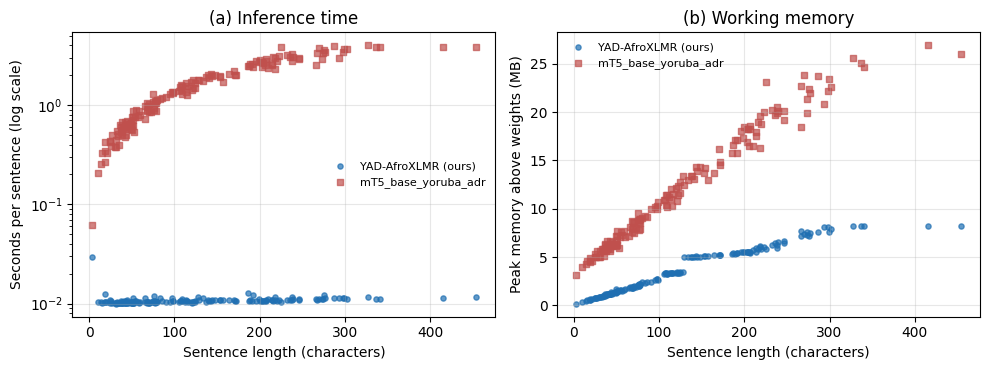

Saved: results/length_scaling.png


In [8]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for model, colour, marker in (('ours', '#1f6fb2', 'o'), ('mT5', '#c0504d', 's')):
    pts = [r for r in rows if r['model'] == model]
    label = 'YAD-AfroXLMR (ours)' if model == 'ours' else 'mT5_base_yoruba_adr'
    ax[0].scatter([r['chars'] for r in pts], [r['seconds'] for r in pts],
                  s=14, alpha=.7, c=colour, marker=marker, label=label)
    ax[1].scatter([r['chars'] for r in pts], [r['peak extra MB'] for r in pts],
                  s=14, alpha=.7, c=colour, marker=marker, label=label)
ax[0].set_yscale('log')
ax[0].set_xlabel('Sentence length (characters)'); ax[0].set_ylabel('Seconds per sentence (log scale)')
ax[0].set_title('(a) Inference time')
ax[1].set_xlabel('Sentence length (characters)'); ax[1].set_ylabel('Peak memory above weights (MB)')
ax[1].set_title('(b) Working memory')
for a in ax:
    a.grid(alpha=.3); a.legend(frameon=False, fontsize=8)
plt.tight_layout()
fig_path = f'{OUT_DIR}/length_scaling.png'
plt.savefig(fig_path, dpi=300); plt.savefig(fig_path.replace('.png', '.pdf'))
plt.show()
print('Saved:', fig_path)

## B5. Full test set timing

Our model is timed on all 3,330 lines at batch size 1 (FP32) and batch size 16 (FP16), which takes under a minute.

The paper's full-test mT5 timings (**4,727.4 s** at batch size 1, FP32, and **1,361.7 s** at batch size 16, FP16) were measured in a **separate session on the same A100 model**. The mT5 runs below reproduce them but take about 79 and 23 minutes, so they are switched off by default.

In [9]:
RUN_MT5_FULL_BATCH16 = False   # about 23 minutes
RUN_MT5_FULL_BATCH1  = False   # about 79 minutes

def timed(fn, *args):
    torch.cuda.synchronize(); t0 = time.perf_counter()
    r = fn(*args)
    torch.cuda.synchronize()
    return r, time.perf_counter() - t0

N = len(src_lines)
full = []
p1, t1 = timed(lambda xs: [afro_one(s) for s in xs], src_lines)
full.append({'model': 'ours', 'batch': 1, 'precision': 'FP32', 'seconds': round(t1, 1)})
print(f'Ours, batch 1, FP32:  {t1:7.1f} s  ({1000*t1/N:.2f} ms/sentence)')

p16, t16 = timed(afro_batch, src_lines)
full.append({'model': 'ours', 'batch': 16, 'precision': 'FP16', 'seconds': round(t16, 1)})
print(f'Ours, batch 16, FP16: {t16:7.1f} s  ({1000*t16/N:.2f} ms/sentence)')
print(f'Batch-16 FP16 output identical to batch-1 FP32 on {sum(a == b for a, b in zip(p1, p16))} / {N} lines')

if RUN_MT5_FULL_BATCH16:
    _, tm16 = timed(mt5_batch, src_lines)
    full.append({'model': 'mT5', 'batch': 16, 'precision': 'FP16', 'seconds': round(tm16, 1)})
    print(f'mT5, batch 16, FP16:  {tm16:7.1f} s   speed-up {tm16/t16:.0f}x')
if RUN_MT5_FULL_BATCH1:
    _, tm1 = timed(lambda xs: [mt5_one(s)[0] for s in xs], src_lines)
    full.append({'model': 'mT5', 'batch': 1, 'precision': 'FP32', 'seconds': round(tm1, 1)})
    print(f'mT5, batch 1, FP32:   {tm1:7.1f} s   speed-up {tm1/t1:.0f}x')

for r in full:
    r['GPU'] = GPU
save_csv(full, f'{OUT_DIR}/full_test_timing.csv')
print(f'Saved: {OUT_DIR}/full_test_timing.csv')

Ours, batch 1, FP32:     31.9 s  (9.58 ms/sentence)
Ours, batch 16, FP16:     4.9 s  (1.46 ms/sentence)
Batch-16 FP16 output identical to batch-1 FP32 on 3306 / 3330 lines
Saved: results/full_test_timing.csv


## B6. Windowed inference for all six configurations

Each sentence longer than the limit is split at spaces into windows of at most 254 tokens, each window is labelled, and the labels are joined back together. No window is longer than anything the model saw in training. Inference uses batch size 1 and FP32.

The windows are cut using AfroXLMR token counts, and B7 applies the **same windows** to mT5, so both systems see identical pieces of text.

Each configuration is loaded from Hugging Face, every test line is labelled, and the result is compared with the released file in `predictions/`.

In [10]:
def token_counts(chars):
    """How many tokens each character becomes (no special tokens)."""
    enc = afro_tok([chars], is_split_into_words=True, add_special_tokens=False)
    counts = [0] * len(chars)
    for w in enc.word_ids(0):
        if w is not None:
            counts[w] += 1
    return counts

def split_windows(chars, counts, limit):
    """(start, end) windows of at most `limit` tokens, cut at spaces where possible."""
    windows, start, used, last_space, i = [], 0, 0, None, 0
    while i < len(chars):
        c = counts[i]
        if used + c > limit and i > start:
            cut = last_space + 1 if last_space is not None and last_space >= start else i
            if cut <= start:
                cut = i
            windows.append((start, cut))
            start = cut
            used = sum(counts[start:i])
            last_space = max((k for k in range(start, i) if chars[k] == ' '), default=None)
            continue
        used += c
        if chars[i] == ' ':
            last_space = i
        i += 1
    windows.append((start, len(chars)))
    return windows

# The windows depend only on the tokenizer, so they are built once for every model.
WINDOWS = [split_windows(list(s), token_counts(list(s)), LIMIT) for s in src_lines]
pieces, owners = [], []
for li, (s, wins) in enumerate(zip(src_lines, WINDOWS)):
    for a, b in wins:
        pieces.append(list(s)[a:b]); owners.append(li)
print(f'Lines split into more than one window: {sum(len(w) > 1 for w in WINDOWS)} / {len(src_lines)}')

REGEN_DIR = f'{OUT_DIR}/regenerated'
os.makedirs(REGEN_DIR, exist_ok=True)
regen = {}
for name in HF_REPOS:
    del afro; torch.cuda.empty_cache()
    afro = load_checkpoint(name)
    labels = predict_labels(pieces, batch_size=1)
    per_line = [[] for _ in src_lines]
    for li, labs in zip(owners, labels):
        per_line[li].extend(labs)
    regen[name] = [render(list(s), labs) for s, labs in zip(src_lines, per_line)]
    with open(f'{REGEN_DIR}/{name}.txt', 'w', encoding='utf-8') as f:
        f.write('\n'.join(regen[name]))
    kept = sum(strip_marks(p) == s for p, s in zip(regen[name], src_lines))
    match = sum(unicodedata.normalize('NFC', a) == unicodedata.normalize('NFC', b)
                for a, b in zip(regen[name], released[name]))
    print(f'{name:<3} letters preserved {kept} / {len(src_lines)}   matches released file {match} / {len(src_lines)}')

del afro; torch.cuda.empty_cache()
afro = load_checkpoint('A')   # leave Configuration A loaded

Lines split into more than one window: 73 / 3330


config.json:   0%|          | 0.00/1.04k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

B0  letters preserved 3330 / 3330   matches released file 3330 / 3330


... (19 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

C   letters preserved 3330 / 3330   matches released file 3330 / 3330


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

## B7. Windowed inference for mT5

mT5 is re-run only on the sentences that B6 split, using the same split points, greedy decoding, batch size 1 and maximum length 256. The window outputs are joined with a space. Every other line is unchanged from the single-window run, so it is taken from the released file.

In [11]:
mt5_regen = list(released['mT5'])
split_idx = [li for li, wins in enumerate(WINDOWS) if len(wins) > 1]
for li in split_idx:
    chars = list(src_lines[li])
    outs = [mt5_one(''.join(chars[a:b]).strip())[0].strip() for a, b in WINDOWS[li]]
    mt5_regen[li] = ' '.join(outs)
regen['mT5'] = mt5_regen
with open(f'{REGEN_DIR}/mT5.txt', 'w', encoding='utf-8') as f:
    f.write('\n'.join(mt5_regen))

match = sum(mt5_regen[li] == released['mT5'][li] for li in split_idx)
print(f'mT5 lines re-run in windows: {len(split_idx)}')
print(f'Re-run lines matching the released file: {match} / {len(split_idx)}')

mT5 lines re-run in windows: 73
Re-run lines matching the released file: 73 / 73


## B8. Score the regenerated predictions

The regenerated predictions are scored with the same scorer as `evaluate.ipynb`, so the table should match the paper's results table.

> **Not yet run in this version.** This cell was rewritten for the public release (it now checks against the released prediction files). Expected result: B0 0.1400, B1 0.1088, B2 0.1014, B3 0.0997, A 0.0956, C 0.0973 and mT5 0.0796 DER, with letters preserved on all 3,330 lines for the six configurations.

In [12]:
print(f"{'System':<6}{'CER':>8}{'WER':>8}{'DER':>8}{'WDER':>8}{'BLEU':>8}{'ChrF':>8}")
print('-' * 54)
for name in SYSTEMS:
    r = score_folded(gold_lines, regen[name])
    print(f'{name:<6}' + ''.join(f'{r[k]:>8.4f}' for k in r))

print(f"\n{'System':<6}{'unchanged':>11}{'words changed':>15}{'words altered':>15}{'non-Yoruba':>12}")
for name in SYSTEMS:
    p = preservation(src_lines, regen[name])
    print(f"{name:<6}{p['lines unchanged']:>11}{p['lines with words changed']:>15}"
          f"{p['words altered']:>15}{p['non-Yoruba marks']:>12}")

System     CER     WER     DER    WDER    BLEU    ChrF
------------------------------------------------------
B0      0.0617  0.2260  0.1400  0.2305  0.5502  0.7718
B1      0.0479  0.1808  0.1088  0.1851  0.6284  0.8172
B2      0.0445  0.1696  0.1014  0.1742  0.6473  0.8279
B3      0.0424  0.1583  0.0997  0.1647  0.6678  0.8338
A       0.0410  0.1537  0.0956  0.1591  0.6760  0.8397
C       0.0418  0.1565  0.0973  0.1622  0.6717  0.8365
mT5     0.0462  0.1423  0.0796  0.1371  0.7042  0.8542

System  unchanged  words changed  words altered  non-Yoruba
B0           3330              0              0           0
B1           3330              0              0           0
B2           3330              0              0           0
B3           3330              0              0           0
A            3330              0              0           0
C            3330              0              0           0
mT5          1954            826           1311          21
